# Phase 5 — Evaluation

**This is the only phase that reads `moods`, `genres`, and `themes`.**

## Metrics
| Metric | Description |
|---|---|
| Quadrant Precision@K | % of top-K in the same emotion quadrant as query |
| Mean AV Distance@K | Euclidean distance in AV space between query and top-K |
| Intra-result Diversity@K | Mean pairwise AV distance within top-K (clone detection) |
| Genre Diversity@K | % of top-K with no genre overlap with the query |

## Experiments
1. **Ablation table** — all strategies × both split schemes (70/15/15 and 40/30/30)
2. **Late-fusion α sweep** — α ∈ {0.2, 0.4, 0.5, 0.6, 0.8} on val split
3. **Cold-start simulation** — 20% of tracks held out from index entirely

In [15]:
import os
import warnings
import numpy as np
import pandas as pd
import faiss
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from tqdm import tqdm

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR   = os.path.join(ROOT, 'outputs')
FAISS_DIR = os.path.join(OUT_DIR, 'faiss_index')

K_LIST = [5, 10, 20]
ALPHAS = [0.2, 0.4, 0.5, 0.6, 0.8]

QUADRANT_COLORS = {'Q1': '#f4a261', 'Q2': '#e63946', 'Q3': '#457b9d', 'Q4': '#2a9d8f'}
QUADRANT_LABELS = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}

print(f'FAISS {faiss.__version__}  |  K={K_LIST}  |  α={ALPHAS}')

FAISS 1.13.2  |  K=[5, 10, 20]  |  α=[0.2, 0.4, 0.5, 0.6, 0.8]


## 1. Load All Data

In [16]:
# ── Feature arrays ────────────────────────────────────────────────────────────
audio_df  = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet'))
lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
coh_df    = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_scores.parquet'))

clap_arr      = np.vstack(audio_df['audio_clap'].values).astype(np.float32)         # (3232, 512) normalized
clap_raw_arr  = np.vstack(audio_df['audio_clap_raw'].values).astype(np.float32)     # (3232, 512) un-normalized
sbert_arr     = np.vstack(lyrics_df['lyrics_sbert'].values).astype(np.float32)      # (2075, 768) normalized
sbert_raw_arr = np.vstack(lyrics_df['lyrics_sbert_raw'].values).astype(np.float32)  # (2075, 768) un-normalized

# ── FAISS indices ─────────────────────────────────────────────────────────────
audio_index  = faiss.read_index(os.path.join(FAISS_DIR, 'audio_only.index'))
lyrics_index = faiss.read_index(os.path.join(FAISS_DIR, 'lyrics_only.index'))
early_index  = faiss.read_index(os.path.join(FAISS_DIR, 'early_fusion.index'))

audio_meta  = pd.read_parquet(os.path.join(FAISS_DIR, 'audio_only_meta.parquet'))
lyrics_meta = pd.read_parquet(os.path.join(FAISS_DIR, 'lyrics_only_meta.parquet'))
early_meta  = pd.read_parquet(os.path.join(FAISS_DIR, 'early_fusion_meta.parquet'))

# ── Per-song lookups ──────────────────────────────────────────────────────────
audio_pos  = dict(zip(audio_meta['song_id'],  audio_meta['faiss_pos']))
lyrics_pos = dict(zip(lyrics_meta['song_id'], lyrics_meta['faiss_pos']))
early_pos  = dict(zip(early_meta['song_id'],  early_meta['faiss_pos']))

audio_sids  = audio_meta['song_id'].tolist()
lyrics_sids = lyrics_meta['song_id'].tolist()
early_sids  = early_meta['song_id'].tolist()

all_meta = pd.concat([audio_meta, lyrics_meta]).drop_duplicates('song_id')
sid_to_q  = dict(zip(all_meta['song_id'], all_meta['quadrant']))
sid_to_av = {r['song_id']: np.array([r['arousal'], r['valence']], dtype=np.float32)
             for _, r in all_meta.iterrows()}

# ── Genres (Phase 5 only) ─────────────────────────────────────────────────────
def parse_genres(x):
    if isinstance(x, list): return [g.strip() for g in x]
    if isinstance(x, str):  return [g.strip() for g in x.split(',') if g.strip()]
    return []

merged['genre_list'] = merged['genres'].apply(parse_genres)
sid_to_genres = dict(zip(merged['song_id'], merged['genre_list']))

# ── Per-sid vector lookups ────────────────────────────────────────────────────
audio_row = {sid: i for i, sid in enumerate(audio_df['song_id'])}

# early_lookup uses raw (un-normalized) projections concatenated.
# The index stores L2-norm([CLAP_raw; SBERT_raw]), so faiss_query normalizes
# the concatenated raw query vector before searching — giving a non-trivial
# joint similarity that differs from equal-weight late fusion.
mm_sids = lyrics_meta['song_id'].tolist()  # order matches early_fusion index
mm_clap_raw  = np.vstack([clap_raw_arr[audio_row[s]] for s in mm_sids]).astype(np.float32)
mm_early_raw = np.hstack([mm_clap_raw, sbert_raw_arr]).astype(np.float32)  # (2075, 1280)

clap_lookup  = {sid: clap_arr[i]      for i, sid in enumerate(audio_df['song_id'])}
sbert_lookup = {sid: sbert_arr[i]     for i, sid in enumerate(lyrics_df['song_id'])}
early_lookup = {sid: mm_early_raw[i]  for i, sid in enumerate(mm_sids)}  # raw concat

print(f'Loaded: {len(audio_df)} audio  {len(lyrics_df)} lyrics  {len(merged)} merged')
print(f'Indices: audio={audio_index.ntotal}  lyrics={lyrics_index.ntotal}  early={early_index.ntotal}')
print(f'early_lookup uses raw [CLAP_raw;SBERT_raw]  dim={mm_early_raw.shape[1]}')

Loaded: 3232 audio  2075 lyrics  3232 merged
Indices: audio=3232  lyrics=2075  early=2075
early_lookup uses raw [CLAP_raw;SBERT_raw]  dim=1280


In [17]:
def load_split_ids(root, scheme, subset):
    tag   = 'audio' if 'Audio' in root else 'lyrics'
    fname = f'{scheme}_{subset}_{tag}_balanced.csv'
    path  = os.path.join(ROOT, root, 'tvt_dataframes', scheme, fname)
    return set(pd.read_csv(path)['Song'].tolist())

splits = {}
for scheme in ['tvt_70_15_15', 'tvt_40_30_30']:
    for subset in ['train', 'validate', 'test']:
        splits[f'{scheme}_{subset}_audio']  = load_split_ids('MERGE_Audio_Balanced',  scheme, subset)
        splits[f'{scheme}_{subset}_lyrics'] = load_split_ids('MERGE_Lyrics_Balanced', scheme, subset)

mm_sids_set = set(mm_sids)

for scheme, label in [('tvt_70_15_15','70/15/15'), ('tvt_40_30_30','40/30/30')]:
    a_test = splits[f'{scheme}_test_audio']
    a_val  = splits[f'{scheme}_validate_audio']
    mm_test = a_test & mm_sids_set
    mm_val  = a_val  & mm_sids_set
    print(f'{label}:  audio_test={len(a_test)}  mm_test={len(mm_test)}  '
          f'audio_val={len(a_val)}  mm_val={len(mm_val)}')

70/15/15:  audio_test=484  mm_test=397  audio_val=484  mm_val=400
40/30/30:  audio_test=968  mm_test=748  audio_val=968  mm_val=741


## 2. Evaluation Functions

In [18]:
def faiss_query(index, vec, k):
    """L2-normalise vec and return (scores, indices) from index."""
    q = vec.astype(np.float32).reshape(1, -1)
    faiss.normalize_L2(q)
    return index.search(q, k)


def retrieve_all_strategies(sid, K_MAX, ALPHAS):
    """
    Run retrieval for all strategies for one query sid.
    Returns dict: strategy_name -> list[song_id] (ordered by score, self excluded)
    """
    # Query the full index for each strategy so all strategies get the same
    # candidate pool size. Previously early_fusion used K_MAX+5 which could
    # under-sample at large K and made the comparison inconsistent.
    OVS_AUDIO  = audio_index.ntotal  + 5
    OVS_LYRICS = lyrics_index.ntotal + 5
    OVS_EARLY  = early_index.ntotal  + 5
    out = {}

    # ── audio-only ────────────────────────────────────────────────────────────
    a_sids, a_scores_map = [], {}
    if sid in clap_lookup:
        sc, ii = faiss_query(audio_index, clap_lookup[sid], OVS_AUDIO)
        for s, i in zip(sc[0], ii[0]):
            if i >= 0 and audio_sids[i] != sid:
                a_sids.append(audio_sids[i])
                a_scores_map[audio_sids[i]] = float(s)
    out['audio_only'] = a_sids

    # ── lyrics-only ───────────────────────────────────────────────────────────
    l_sids, l_scores_map = [], {}
    if sid in sbert_lookup:
        sc, ii = faiss_query(lyrics_index, sbert_lookup[sid], OVS_LYRICS)
        for s, i in zip(sc[0], ii[0]):
            if i >= 0 and lyrics_sids[i] != sid:
                l_sids.append(lyrics_sids[i])
                l_scores_map[lyrics_sids[i]] = float(s)
    out['lyrics_only'] = l_sids

    # ── early fusion ──────────────────────────────────────────────────────────
    # Query vector is the raw concatenated [CLAP_raw; SBERT_raw]; faiss_query
    # normalizes it before searching, matching how the index was built.
    ef_sids = []
    if sid in early_lookup:
        sc, ii = faiss_query(early_index, early_lookup[sid], OVS_EARLY)
        for s, i in zip(sc[0], ii[0]):
            if i >= 0 and early_sids[i] != sid:
                ef_sids.append(early_sids[i])
    out['early_fusion'] = ef_sids

    # ── late fusion (multiple α) ──────────────────────────────────────────────
    common = set(a_scores_map) & set(l_scores_map)
    for alpha in ALPHAS:
        combined = sorted(
            [(s, alpha * a_scores_map[s] + (1 - alpha) * l_scores_map[s]) for s in common],
            key=lambda x: -x[1]
        )
        out[f'late_{alpha}'] = [s for s, _ in combined]

    return out


def compute_metrics(sids_ordered, query_sid, k):
    """Precision@k, AV-Distance@k, Diversity@k for one (strategy, query, k)."""
    q_quad = sid_to_q.get(query_sid)
    q_av   = sid_to_av.get(query_sid)
    top    = [s for s in sids_ordered if s != query_sid][:k]
    if not top or q_quad is None or q_av is None:
        return dict(precision=np.nan, av_dist=np.nan, diversity=np.nan, genre_div=np.nan)

    precision = sum(1 for s in top if sid_to_q.get(s) == q_quad) / k

    avs = [sid_to_av[s] for s in top if s in sid_to_av]
    av_dist   = float(np.mean([np.linalg.norm(av - q_av) for av in avs])) if avs else np.nan
    diversity = float(np.mean([
        np.linalg.norm(avs[i] - avs[j])
        for i in range(len(avs)) for j in range(i + 1, len(avs))
    ])) if len(avs) >= 2 else 0.0

    q_genres = set(sid_to_genres.get(query_sid, []))
    cross_genre = sum(
        1 for s in top
        if q_genres and not (q_genres & set(sid_to_genres.get(s, [])))
    )
    genre_div = cross_genre / k if q_genres else np.nan

    return dict(precision=precision, av_dist=av_dist, diversity=diversity, genre_div=genre_div)


def evaluate(query_sids, label='eval'):
    """Run all strategies on query_sids. Returns tidy DataFrame."""
    rows = []
    K_MAX = max(K_LIST)
    for sid in tqdm(query_sids, desc=label, ncols=80):
        strat_results = retrieve_all_strategies(sid, K_MAX, ALPHAS)
        for strat, sids_ord in strat_results.items():
            for k in K_LIST:
                m = compute_metrics(sids_ord, sid, k)
                rows.append({'strategy': strat, 'song_id': sid,
                             'quadrant': sid_to_q.get(sid), 'k': k, **m})
    return pd.DataFrame(rows)


def summarise(df):
    """Aggregate per-query results to mean per (strategy, k)."""
    return (
        df.groupby(['strategy', 'k'])[['precision', 'av_dist', 'diversity', 'genre_div']]
        .mean()
        .round(3)
    )

print('Evaluation functions defined.')
print(f'  early_fusion queries full index ({early_index.ntotal} vectors) — consistent with other strategies')

Evaluation functions defined.
  early_fusion queries full index (2075 vectors) — consistent with other strategies


## 3. Evaluation — 70/15/15 Split

- **Audio-only** queries: 484 audio test tracks
- **Lyrics/Early/Late** queries: multimodal test tracks (audio test ∩ lyrics set)

In [19]:
a_test_7015  = splits['tvt_70_15_15_test_audio']
mm_test_7015 = a_test_7015 & mm_sids_set

# Audio-only strategy evaluated on all 484 audio test tracks
# All other strategies evaluated on multimodal test tracks only
# We run evaluate() on mm_test so all strategies are comparable;
# audio_only on full audio_test is run separately for the ablation.
print(f'Running 70/15/15 evaluation on {len(mm_test_7015)} multimodal test tracks ...')
res_7015 = evaluate(list(mm_test_7015), label='70/15/15 test')

# Also eval audio_only on the full 484 audio test tracks (shows audio coverage)
print(f'\nRunning audio-only on all {len(a_test_7015)} audio test tracks ...')
res_7015_audio_full = evaluate(list(a_test_7015), label='70/15/15 audio-full')
res_7015_audio_only = res_7015_audio_full[res_7015_audio_full['strategy'] == 'audio_only']

print('\n=== 70/15/15 — multimodal test (all strategies) ===')
print(summarise(res_7015).to_string())
print('\n=== 70/15/15 — audio-only on full audio test (484 tracks) ===')
print(summarise(res_7015_audio_only).to_string())

Running 70/15/15 evaluation on 397 multimodal test tracks ...


70/15/15 test: 100%|██████████████████████████| 397/397 [00:11<00:00, 35.13it/s]



Running audio-only on all 484 audio test tracks ...


70/15/15 audio-full: 100%|████████████████████| 484/484 [00:10<00:00, 45.26it/s]


=== 70/15/15 — multimodal test (all strategies) ===
                 precision  av_dist  diversity  genre_div
strategy     k                                           
audio_only   5       0.387    0.283      0.289      0.558
             10      0.380    0.284      0.290      0.565
             20      0.375    0.285      0.292      0.567
early_fusion 5       0.631    0.196      0.211      0.412
             10      0.611    0.202      0.216      0.414
             20      0.595    0.208      0.227      0.431
late_0.2     5       0.636    0.195      0.213      0.414
             10      0.621    0.200      0.215      0.413
             20      0.600    0.208      0.226      0.428
late_0.4     5       0.642    0.194      0.211      0.406
             10      0.622    0.200      0.217      0.413
             20      0.609    0.206      0.224      0.430
late_0.5     5       0.647    0.193      0.211      0.408
             10      0.622    0.201      0.218      0.411
             20    

## 4. Evaluation — 40/30/30 Split

In [20]:
a_test_4030  = splits['tvt_40_30_30_test_audio']
mm_test_4030 = a_test_4030 & mm_sids_set

print(f'Running 40/30/30 evaluation on {len(mm_test_4030)} multimodal test tracks ...')
res_4030 = evaluate(list(mm_test_4030), label='40/30/30 test')

print('\n=== 40/30/30 — multimodal test (all strategies) ===')
print(summarise(res_4030).to_string())

Running 40/30/30 evaluation on 748 multimodal test tracks ...


40/30/30 test: 100%|██████████████████████████| 748/748 [00:20<00:00, 36.64it/s]



=== 40/30/30 — multimodal test (all strategies) ===
                 precision  av_dist  diversity  genre_div
strategy     k                                           
audio_only   5       0.394    0.286      0.282      0.560
             10      0.386    0.287      0.285      0.564
             20      0.381    0.288      0.289      0.566
early_fusion 5       0.624    0.200      0.210      0.413
             10      0.607    0.207      0.219      0.418
             20      0.593    0.213      0.229      0.429
late_0.2     5       0.624    0.200      0.212      0.416
             10      0.614    0.206      0.218      0.419
             20      0.597    0.213      0.230      0.429
late_0.4     5       0.632    0.199      0.212      0.412
             10      0.617    0.204      0.218      0.418
             20      0.603    0.211      0.227      0.432
late_0.5     5       0.634    0.198      0.212      0.412
             10      0.618    0.205      0.218      0.416
             20    

## 5. Late-Fusion α Sweep (validation split)

Tune α on the **validation** set so the test results above remain uncontaminated.

In [21]:
mm_val_7015 = splits['tvt_70_15_15_validate_audio'] & mm_sids_set
print(f'Val set: {len(mm_val_7015)} multimodal tracks')
res_val = evaluate(list(mm_val_7015), label='val α-sweep')

late_val = res_val[res_val['strategy'].str.startswith('late_')]
alpha_summary = (
    late_val[late_val['k'] == 10]
    .groupby('strategy')[['precision', 'av_dist', 'diversity']]
    .mean()
    .round(3)
    .sort_values('precision', ascending=False)
)
print('\nLate fusion α comparison @ K=10 (validation split):')
print(alpha_summary.to_string())
best_alpha = float(alpha_summary.index[0].split('_')[1])
print(f'\nBest α by Precision@10: {best_alpha}')

Val set: 400 multimodal tracks


val α-sweep: 100%|████████████████████████████| 400/400 [00:11<00:00, 36.32it/s]



Late fusion α comparison @ K=10 (validation split):
          precision  av_dist  diversity
strategy                               
late_0.4      0.594    0.207      0.221
late_0.2      0.591    0.207      0.221
late_0.6      0.591    0.208      0.222
late_0.5      0.589    0.208      0.220
late_0.8      0.586    0.210      0.227

Best α by Precision@10: 0.4


## 6. Ablation Table

Multimodal test queries only (fair comparison across all strategies).  
**Baseline:** chance Precision = 0.25 (4 balanced quadrants).

In [22]:
STRATEGY_ORDER = ['audio_only', 'lyrics_only',
                  'late_0.2', 'late_0.4', 'late_0.5', 'late_0.6', 'late_0.8',
                  'early_fusion']

def ablation_row(df, strategy, k):
    sub = df[(df['strategy'] == strategy) & (df['k'] == k)]
    if sub.empty:
        return [np.nan] * 4
    return [sub['precision'].mean(), sub['av_dist'].mean(),
            sub['diversity'].mean(), sub['genre_div'].mean()]

rows = []
for strat in STRATEGY_ORDER:
    for split_label, df in [('70/15/15', res_7015), ('40/30/30', res_4030)]:
        for k in [5, 10]:
            p, d, div, gd = ablation_row(df, strat, k)
            rows.append({
                'Strategy': strat, 'Split': split_label, 'K': k,
                'Precision': round(p, 3), 'AV_Dist': round(d, 3),
                'Diversity': round(div, 3), 'Genre_Div': round(gd, 3),
            })

ablation = pd.DataFrame(rows)

# Pivot to wide format for paper-ready table
wide = ablation.pivot_table(
    index='Strategy',
    columns=['Split', 'K'],
    values=['Precision', 'AV_Dist', 'Diversity', 'Genre_Div'],
    aggfunc='first',
)[['Precision', 'AV_Dist', 'Diversity', 'Genre_Div']]
wide = wide.reindex(STRATEGY_ORDER)

print('=== ABLATION TABLE ===')
print(f'(Chance Precision = 0.25 | Multimodal test queries)')
print()
print(wide.to_string())

# Save to CSV for reference
ablation.to_csv(os.path.join(OUT_DIR, 'ablation_table.csv'), index=False)
print('\nSaved: ablation_table.csv')

=== ABLATION TABLE ===
(Chance Precision = 0.25 | Multimodal test queries)

             Precision                         AV_Dist                        Diversity                        Genre_Div                       
Split         40/30/30        70/15/15        40/30/30        70/15/15         40/30/30        70/15/15         40/30/30        70/15/15       
K                   5      10       5      10       5      10       5      10        5      10       5      10        5      10       5      10
Strategy                                                                                                                                       
audio_only       0.394  0.386    0.387  0.380    0.286  0.287    0.283  0.284     0.282  0.285    0.289  0.290     0.560  0.564    0.558  0.565
lyrics_only      0.623  0.604    0.629  0.608    0.200  0.207    0.195  0.201     0.210  0.218    0.210  0.216     0.411  0.418    0.408  0.414
late_0.2         0.624  0.614    0.636  0.621    0.200  0.20

## 7. Cold-Start Simulation

Hold out **20% of all tracks** from the FAISS index entirely.  
Build a reduced index with the remaining 80%, then query each held-out track.  
This directly replicates cold-start: the query track has **never been indexed**.

In [23]:
rng = np.random.default_rng(42)

# ── Hold-out split ────────────────────────────────────────────────────────────
all_mm = np.array(mm_sids)
holdout_idx = rng.choice(len(all_mm), size=int(0.2 * len(all_mm)), replace=False)
holdout_mask = np.zeros(len(all_mm), dtype=bool)
holdout_mask[holdout_idx] = True

cs_holdout = all_mm[holdout_mask].tolist()   # ~415 query tracks
cs_index_sids = all_mm[~holdout_mask].tolist()  # ~1660 indexed tracks

print(f'Cold-start: {len(cs_holdout)} held-out queries  |  {len(cs_index_sids)} in index')

# ── Build reduced indices ─────────────────────────────────────────────────────
def build_subset_index(vecs_dict, subset_sids):
    """Build a normalized IndexFlatIP from a subset of song_ids."""
    X = np.vstack([vecs_dict[s] for s in subset_sids]).astype(np.float32)
    faiss.normalize_L2(X)
    idx = faiss.IndexFlatIP(X.shape[1])
    idx.add(X)
    return idx, {s: i for i, s in enumerate(subset_sids)}, subset_sids

cs_audio_idx, cs_audio_pos, cs_audio_sids  = build_subset_index(clap_lookup,  cs_index_sids)
cs_lyrics_idx, cs_lyrics_pos, cs_lyrics_sids = build_subset_index(sbert_lookup, cs_index_sids)
cs_early_vecs = {s: early_lookup[s] for s in cs_index_sids}
cs_early_idx, cs_early_pos, cs_early_sids   = build_subset_index(cs_early_vecs, cs_index_sids)

print(f'Reduced indices: audio={cs_audio_idx.ntotal}  lyrics={cs_lyrics_idx.ntotal}  early={cs_early_idx.ntotal}')

# ── Cold-start evaluation ─────────────────────────────────────────────────────
# Temporarily swap global indices and position maps
_saved = (audio_index, audio_pos, audio_sids,
          lyrics_index, lyrics_pos, lyrics_sids,
          early_index, early_pos, early_sids)

audio_index,  audio_pos,  audio_sids  = cs_audio_idx,  cs_audio_pos,  cs_audio_sids
lyrics_index, lyrics_pos, lyrics_sids = cs_lyrics_idx, cs_lyrics_pos, cs_lyrics_sids
early_index,  early_pos,  early_sids  = cs_early_idx,  cs_early_pos,  cs_early_sids

res_coldstart = evaluate(cs_holdout, label='cold-start')

# Restore original indices
(audio_index, audio_pos, audio_sids,
 lyrics_index, lyrics_pos, lyrics_sids,
 early_index, early_pos, early_sids) = _saved

print('\n=== Cold-start results (K=10) ===')
cs_summary = (
    res_coldstart[res_coldstart['k'] == 10]
    .groupby('strategy')[['precision', 'av_dist', 'diversity']]
    .mean().round(3)
    .reindex([s for s in STRATEGY_ORDER if s in res_coldstart['strategy'].unique()])
)
print(cs_summary.to_string())
print(f'\n(Chance = 0.25 | n_queries={len(cs_holdout)})')

Cold-start: 415 held-out queries  |  1660 in index
Reduced indices: audio=1660  lyrics=1660  early=1660


cold-start: 100%|█████████████████████████████| 415/415 [00:09<00:00, 45.11it/s]



=== Cold-start results (K=10) ===
              precision  av_dist  diversity
strategy                                   
audio_only        0.397    0.279      0.278
lyrics_only       0.580    0.209      0.219
late_0.2          0.582    0.208      0.220
late_0.4          0.587    0.208      0.223
late_0.5          0.589    0.207      0.222
late_0.6          0.587    0.207      0.223
late_0.8          0.594    0.208      0.223
early_fusion      0.579    0.209      0.220

(Chance = 0.25 | n_queries=415)


## 8. Cross-Genre Analysis

A key claim of content-based cold-start: recommendations surface **emotionally similar tracks across genre boundaries**.  
Here we check what fraction of top-K retrievals have **no genre overlap** with the query.

In [24]:
# Genre diversity by quadrant and strategy (K=10, 70/15/15 test)
gd = (
    res_7015[res_7015['k'] == 10]
    .groupby(['strategy', 'quadrant'])['genre_div']
    .mean()
    .unstack('quadrant')
    .reindex(STRATEGY_ORDER)
    .round(3)
)
print('=== Cross-Genre Rate@10 (fraction of top-10 with no genre overlap) ===')
print(gd.to_string())

# Top-5 cross-genre emotional twin examples for best strategy
print(f'\n=== Cross-Genre Emotional Twin Gallery (early_fusion, Q1 Happy) ===')
q1_test = [s for s in mm_test_7015 if sid_to_q.get(s) == 'Q1']
np.random.seed(0)
sample_q1 = np.random.choice(q1_test, size=min(3, len(q1_test)), replace=False)

for qsid in sample_q1:
    q_genres = sid_to_genres.get(qsid, [])
    q_row = merged[merged['song_id'] == qsid].iloc[0] if len(merged[merged['song_id'] == qsid]) else None
    q_title  = q_row['title']  if q_row is not None else '?'
    q_artist = q_row['artist'] if q_row is not None else '?'
    print(f'\nQuery: [{q_artist}] "{q_title}"  genres={q_genres[:3]}')

    strat_res = retrieve_all_strategies(qsid, 10, ALPHAS)
    ef_hits   = strat_res['early_fusion'][:5]
    for hid in ef_hits:
        h_row = merged[merged['song_id'] == hid]
        if h_row.empty: continue
        h_row = h_row.iloc[0]
        h_genres = sid_to_genres.get(hid, [])
        cross = '★ cross-genre' if not (set(q_genres) & set(h_genres)) else ''
        print(f'  [{h_row["artist"]}] "{h_row["title"]}"  {sid_to_q.get(hid)}  genres={h_genres[:3]}  {cross}')

=== Cross-Genre Rate@10 (fraction of top-10 with no genre overlap) ===
quadrant         Q1     Q2     Q3     Q4
strategy                                
audio_only    0.592  0.420  0.601  0.651
lyrics_only   0.453  0.206  0.526  0.478
late_0.2      0.449  0.200  0.536  0.474
late_0.4      0.450  0.193  0.537  0.480
late_0.5      0.446  0.194  0.530  0.481
late_0.6      0.449  0.195  0.534  0.486
late_0.8      0.457  0.181  0.536  0.488
early_fusion  0.452  0.207  0.528  0.476

=== Cross-Genre Emotional Twin Gallery (early_fusion, Q1 Happy) ===

Query: [Elvis Presley] "Just Because"  genres=['Country', 'Pop/Rock']
  [Paul McCartney] "Just Because"  Q1  genres=['Electronic', 'Pop/Rock']  
  [Boney James] "Santa Baby"  Q4  genres=['Easy Listening', 'Holiday', 'Jazz']  ★ cross-genre
  [Ida Cox] "Cherry Pickin' Blues"  Q3  genres=['Blues', 'Jazz']  ★ cross-genre
  [Louis Armstrong] "My Sweet Hunk O' Trash"  Q1  genres=['Jazz']  ★ cross-genre
  [Furry Lewis] "Baby You Don't Want Me"  Q3  gen

## 9. Visualisation

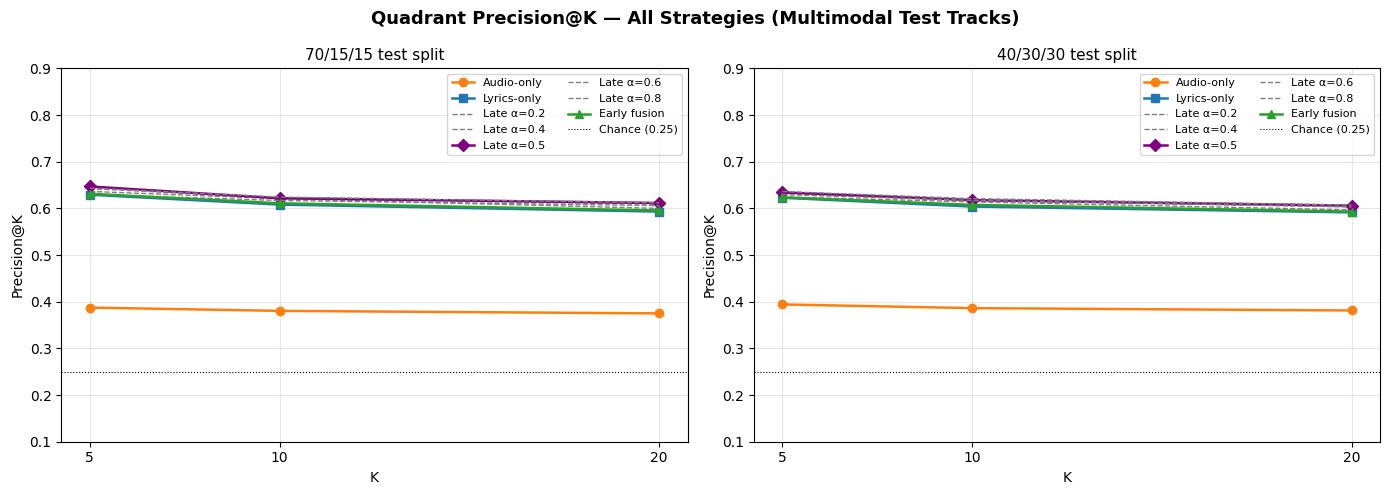

Saved: precision_at_k.png


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Quadrant Precision@K — All Strategies (Multimodal Test Tracks)',
             fontsize=13, fontweight='bold')

STRATEGY_STYLES = {
    'audio_only':   ('tab:orange', '-',  'o', 'Audio-only'),
    'lyrics_only':  ('tab:blue',   '-',  's', 'Lyrics-only'),
    'late_0.2':     ('gray',       '--', None, 'Late α=0.2'),
    'late_0.4':     ('gray',       '--', None, 'Late α=0.4'),
    'late_0.5':     ('purple',     '-',  'D', 'Late α=0.5'),
    'late_0.6':     ('gray',       '--', None, 'Late α=0.6'),
    'late_0.8':     ('gray',       '--', None, 'Late α=0.8'),
    'early_fusion': ('tab:green',  '-',  '^', 'Early fusion'),
}

for ax, (res_df, split_label) in zip(axes, [
    (res_7015, '70/15/15'), (res_4030, '40/30/30')
]):
    for strat, (color, ls, marker, label) in STRATEGY_STYLES.items():
        sub = res_df[res_df['strategy'] == strat].groupby('k')['precision'].mean()
        if sub.empty: continue
        ax.plot(sub.index, sub.values, color=color, linestyle=ls,
                marker=marker, markersize=6, label=label, linewidth=1.8 if marker else 1.0)
    ax.axhline(0.25, color='black', linestyle=':', linewidth=0.8, label='Chance (0.25)')
    ax.set_xlabel('K', fontsize=10)
    ax.set_ylabel('Precision@K', fontsize=10)
    ax.set_title(f'{split_label} test split', fontsize=11)
    ax.set_xticks(K_LIST)
    ax.set_ylim(0.1, 0.9)
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'precision_at_k.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: precision_at_k.png')

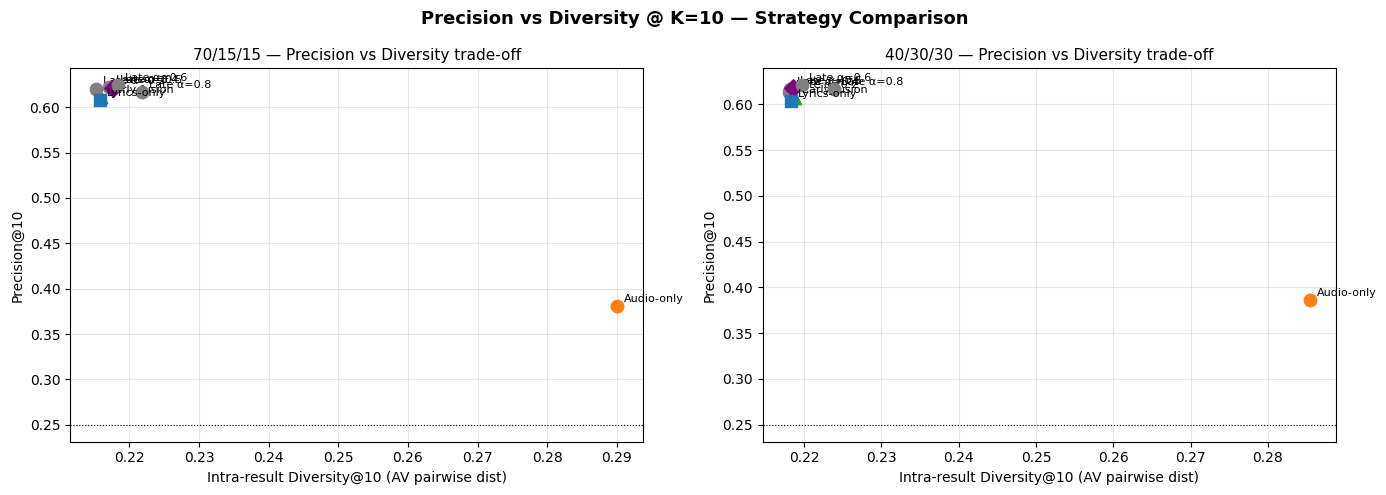

Saved: precision_diversity_tradeoff.png


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Precision vs Diversity @ K=10 — Strategy Comparison',
             fontsize=13, fontweight='bold')

for ax, (res_df, split_label) in zip(axes, [
    (res_7015, '70/15/15'), (res_4030, '40/30/30')
]):
    sub = res_df[res_df['k'] == 10].groupby('strategy')[['precision','diversity']].mean()
    for strat, row in sub.iterrows():
        color, ls, marker, label = STRATEGY_STYLES.get(strat, ('gray', '-', 'o', strat))
        ax.scatter(row['diversity'], row['precision'], color=color,
                   marker=marker or 'o', s=80, zorder=3)
        ax.annotate(label, (row['diversity'], row['precision']),
                    textcoords='offset points', xytext=(5, 3), fontsize=8)
    ax.axhline(0.25, color='black', linestyle=':', linewidth=0.8)
    ax.set_xlabel('Intra-result Diversity@10 (AV pairwise dist)', fontsize=10)
    ax.set_ylabel('Precision@10', fontsize=10)
    ax.set_title(f'{split_label} — Precision vs Diversity trade-off', fontsize=11)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'precision_diversity_tradeoff.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: precision_diversity_tradeoff.png')

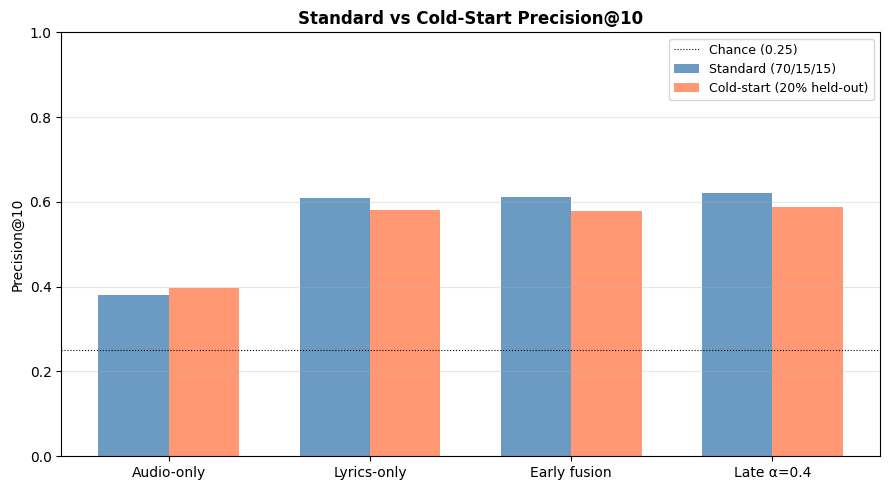

Saved: coldstart_comparison.png


In [27]:
# Cold-start vs standard comparison bar chart
compare_strats = ['audio_only', 'lyrics_only', 'early_fusion', f'late_{best_alpha}']

std_prec = [
    res_7015[(res_7015['strategy'] == s) & (res_7015['k'] == 10)]['precision'].mean()
    for s in compare_strats
]
cs_prec = [
    res_coldstart[(res_coldstart['strategy'] == s) & (res_coldstart['k'] == 10)]['precision'].mean()
    for s in compare_strats
]

x = np.arange(len(compare_strats))
w = 0.35
labels = ['Audio-only', 'Lyrics-only', 'Early fusion', f'Late α={best_alpha}']

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - w/2, std_prec, w, label='Standard (70/15/15)', color='steelblue', alpha=0.8)
ax.bar(x + w/2, cs_prec,  w, label='Cold-start (20% held-out)', color='coral',     alpha=0.8)
ax.axhline(0.25, color='black', linestyle=':', linewidth=0.8, label='Chance (0.25)')
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylabel('Precision@10', fontsize=10)
ax.set_title('Standard vs Cold-Start Precision@10', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.set_ylim(0, 1.0)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coldstart_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: coldstart_comparison.png')

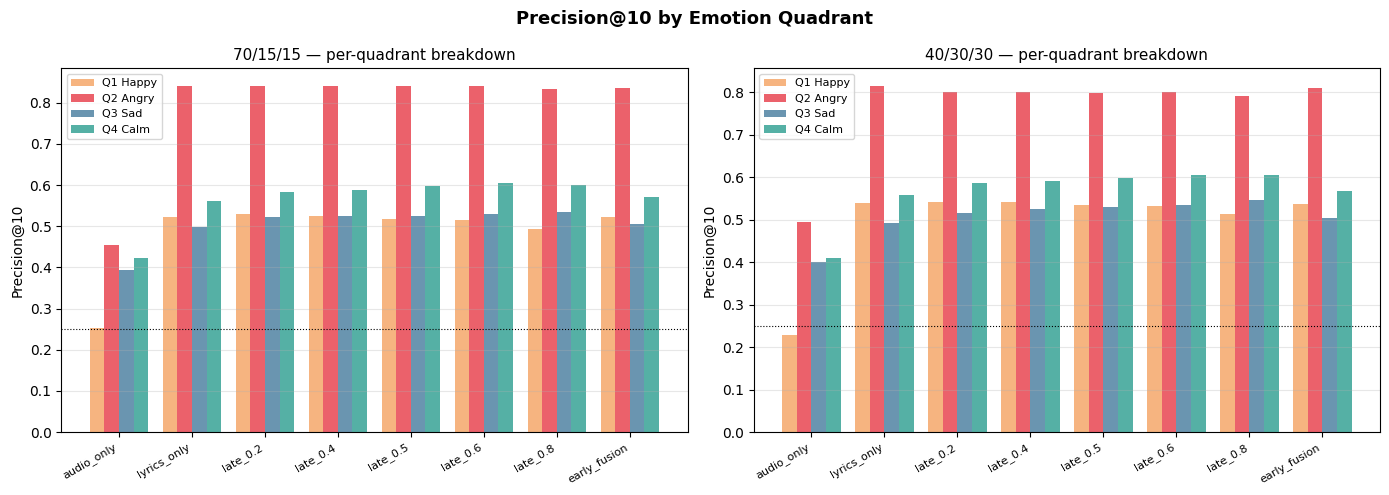

Saved: per_quadrant_precision.png


In [28]:
# Per-quadrant Precision@10 for each strategy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Precision@10 by Emotion Quadrant', fontsize=13, fontweight='bold')

for ax, (res_df, split_label) in zip(axes, [
    (res_7015, '70/15/15'), (res_4030, '40/30/30')
]):
    sub = (
        res_df[res_df['k'] == 10]
        .groupby(['strategy', 'quadrant'])['precision'].mean()
        .unstack('quadrant')
        .reindex([s for s in STRATEGY_ORDER if s in res_df['strategy'].unique()])
    )
    x = np.arange(len(sub))
    w = 0.2
    for j, q in enumerate(['Q1', 'Q2', 'Q3', 'Q4']):
        if q in sub.columns:
            ax.bar(x + j * w, sub[q], w, color=QUADRANT_COLORS[q],
                   alpha=0.8, label=f'{q} {QUADRANT_LABELS[q]}')
    ax.axhline(0.25, color='black', linestyle=':', linewidth=0.8)
    ax.set_xticks(x + 1.5 * w)
    ax.set_xticklabels(sub.index, rotation=30, ha='right', fontsize=8)
    ax.set_ylabel('Precision@10', fontsize=10)
    ax.set_title(f'{split_label} — per-quadrant breakdown', fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'per_quadrant_precision.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: per_quadrant_precision.png')

## Phase 5 Complete

### Key outputs
| File | Contents |
|---|---|
| `ablation_table.csv` | Full ablation: strategy × split × K × metric |
| `precision_at_k.png` | Precision@K curves for all strategies |
| `precision_diversity_tradeoff.png` | Precision vs diversity scatter |
| `coldstart_comparison.png` | Standard vs cold-start bar chart |
| `per_quadrant_precision.png` | Per-quadrant precision breakdown |

### Research claims tested
- **Does fusion beat unimodal?** → Check if early/late fusion Precision > audio_only and lyrics_only
- **Does lyrics add value?** → Check if lyrics_only or fused > audio_only
- **Does cold-start hold?** → Check if cold-start Precision stays well above 0.25 (chance)
- **Q2 hardest quadrant?** → Check per-quadrant plot for lowest Angry precision

**Next:** Phase 6 — Visualisation & Writeup (`phase6_visualization.ipynb`)